# Analyzing your ODIN data

You have measured with the virtual ODIN (web page, console or NICOS). This notebook takes your files and goes, step by
step, from the raw neutrons to a physical result: the distance between the atomic planes of iron, read from a
**Bragg edge**.

**What you will do**
1. find your files and the logbook of the session;
2. look inside a NeXus file: what the detector really records;
3. compare the raw counts of the open beam and of the sample;
4. reduce the data with the official ESS software: the **transmission** $T(\lambda)$ and the transmission image;
5. find the Bragg edges in $T(\lambda)$ and deduce the distance $d$ between atomic planes.

Run the cells one after the other (*Shift + Enter*). Only the next cell needs your input.

## 1. Your folder

Write in `FOLDER` the folder of your measurements:
- web page or console: `f"{TWIN_RUN_ROOT}/odin/<session>"`, e.g. `f"{TWIN_RUN_ROOT}/odin/my_first_session"`;
- NICOS: the folder of your proposal, `f"{TWIN_RUN_ROOT}/data/odin/<year>/<proposal>/raw"`,
  e.g. `f"{TWIN_RUN_ROOT}/data/odin/2026/1234/raw"`.

`TWIN_RUN_ROOT` is the root of the results of the twin (`/data/twin` in the container,
`C:\Users\<you>\McStas_runs\twin` on Windows). With `FOLDER = None` (remove the `#` in front of it and put one in
front of the other `FOLDER` line), the notebook measures a small demonstration session first (dark, open beam, iron
plate, 10 s each; about 1 min).

In [1]:
from odin_paths import TWIN_RUN_ROOT          # root of the results of the twins
# FOLDER = None                                  # or e.g. f"{TWIN_RUN_ROOT}/data/odin/2026/1234/raw"
FOLDER = f"{TWIN_RUN_ROOT}/data/odin/2026/1234/raw"

In [2]:
import sys, os, json, glob, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))
import numpy as np
import scipp as sc
import h5py
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import erfc
from odin_paths import TWIN_RUN_ROOT
import odin_reduction as red

if FOLDER is None:                                     # demonstration session
    FOLDER = f"{TWIN_RUN_ROOT}/odin/analysis_demo"
    if not red.data_files(FOLDER):
        from odin_virtual import VirtualOdin
        odin = VirtualOdin(session="analysis_demo", seed=1)
        odin.count(10, title="dark")                    # shutter closed at start-up
        odin.move(shutter="open", stage_x=0.5)          # sample 50 cm aside: out of the field of view
        odin.count(10, title="open beam")
        odin.move(stage_x=0.0)                          # sample back in the beam
        odin.count(10, title="iron plate")
print("folder:", FOLDER)
print("files :", [os.path.basename(f) for f in red.data_files(FOLDER)])

folder: C:/Users/agrgl/McStas_runs/twin/data/odin/2026/1234/raw
files : ['odin_000001.nxs', 'odin_000002.nxs', 'odin_000003.nxs', 'odin_000004.nxs', 'odin_000005.nxs', 'odin_000006.nxs', 'odin_000007.nxs', 'odin_000008.nxs', 'odin_000009.nxs', 'odin_000010.nxs', 'odin_000011.nxs', 'odin_000012.nxs', 'odin_000013.nxs', 'odin_000014.nxs', 'odin_000015.nxs', 'odin_000016.nxs', 'odin_000017.nxs', 'odin_000018.nxs', 'odin_000019.nxs', 'odin_000020.nxs', 'odin_000021.nxs', 'odin_000022.nxs', 'odin_000023.nxs', 'odin_000024.nxs']


## 2. The logbook: which file is what?

As at ESS, each `nexusfile_open` block in NICOS wrote **one file**, written by the ESS file writer
(`odin_job_000001.hdf`, `odin_job_000002.hdf`, ...). Everything is in the file: its title, and the state of the instrument
during the measurement (shutter, sample stage, pinhole, choppers). The table below is read from the files themselves.

To compute a transmission you need three kinds of measurement:
- **dark**: shutter closed. The detector still records a few counts (gamma rays, electronic noise): the background,
  to be subtracted from the two others;
- **open beam**: shutter open, sample out of the beam (`stage_x` far from 0: the field of view is only 14 mm wide).
  It tells how many neutrons of each wavelength arrive *without* the sample;
- **sample**: shutter open, sample in the beam (`stage_x` = 0).

The column `kind` is guessed from the shutter and the stage position. Check it against what you did.

In [3]:
rows = red.measurements(FOLDER)                         # the logbook, read from the files
def show_table(rows):                                  # a list of dicts, printed as a table
    if not rows:
        print("no measurement in the logbook"); return
    cols = list(rows[0])
    width = {c: max(len(c), *(len(str(r.get(c, ""))) for r in rows)) for c in cols}
    print("  ".join(c.ljust(width[c]) for c in cols))
    for r in rows:
        print("  ".join(str(r.get(c, "")).ljust(width[c]) for c in cols))

show_table(rows)

file             kind       title                t_s   counts    choppers  wfm_delta_m  pinhole_m  stage_x_m  stage_rot_deg
odin_000001.nxs  open beam  open beam            5.0   2708733   wfm       0.3          0.03       0.5        0.0          
odin_000002.nxs  sample     iron plate           5.0   2154214   wfm       0.3          0.03       0.0        0.0          
odin_000003.nxs  dark       iron plate           2.0   16        wfm       0.3          0.03       0.0        0.0          
odin_000004.nxs  open beam  open beam via NICOS  5.0   890558    wfm       0.1          0.03       0.5        0.0          
odin_000005.nxs  dark       dark                 10.0  99        wfm       0.3          0.03       0.0        0.0          
odin_000006.nxs  open beam  open beam            10.0  5408439   wfm       0.3          0.03       0.5        0.0          
odin_000007.nxs  sample     iron plate           10.0  4294807   wfm       0.3          0.03       0.0        0.0          
odin_000

The cell below picks the **last** dark, open beam and sample of the logbook. To choose other files (for example an
older set, or another chopper mode), write their names instead, e.g. `SAMPLE = "odin_job_000003.hdf"`.
Dark, open beam and sample must be measured with the **same chopper mode and pinhole**: otherwise the ratio mixes two
different beams and means nothing.

In [4]:
def last(kind):
    names = [r["file"] for r in rows if r["kind"] == kind]
    return names[-1] if names else None

DARK, OPEN, SAMPLE = last("dark"), last("open beam"), last("sample")
print(f"dark: {DARK}   open beam: {OPEN}   sample: {SAMPLE}")
if OPEN is None or SAMPLE is None:
    print("An open beam and a sample measurement are needed: measure them, then run this notebook again.")
settings = {(r["choppers"], r["wfm_delta_m"], r["pinhole_m"]) for r in rows if r["file"] in (DARK, OPEN, SAMPLE)}
if len(settings) > 1:
    print("WARNING: these files were not measured with the same chopper mode and pinhole:", settings)
path = lambda name: f"{FOLDER}/{name}" if name else None

dark: odin_000024.nxs   open beam: odin_000022.nxs   sample: odin_000023.nxs


## 3. Inside a NeXus file

The files have the format of the real ODIN at ESS (NeXus, built on HDF5: a file organized like folders and
sub-folders). The detector (`timepix3`) does not record an image: it records **each neutron**, one by one, as an
*event*:
- `event_id`: the pixel hit;
- `event_time_offset`: the arrival time of the neutron, counted from the start of its source pulse (ESS sends
  14 pulses per second);
- `event_time_zero` / `event_index`: when each pulse happened and which events belong to it.

The cell below prints an extract of the open-beam file: the first source pulses, then the first five neutrons, exactly
as they are stored.

In [5]:
import datetime
with h5py.File(path(OPEN), "r") as f:
    det = f["entry/instrument/timepix3"]
    t_zero = det["data/event_time_zero"][:3]       # ns since 1 January 1970 (UTC)
    index = det["data/event_index"][:3]
    ids = det["data/event_id"][:5]
    toa = det["data/event_time_offset"][:5]        # ns after the start of the pulse
    x_off, y_off = det["x_pixel_offset"][()], det["y_pixel_offset"][()]    # pixel centers [m]

print("source pulses")
print("  pulse   event_time_zero [ns]   = date and time (UTC)            event_index (first event of the pulse)")
for k, (tz, i0) in enumerate(zip(t_zero, index)):
    date = datetime.datetime.fromtimestamp(tz / 1e9, datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S.%f")
    print(f"  {k:5d}   {tz:20d}   {date}   {i0:10d}")
print("\nfirst neutrons (all in pulse 0)")
print("  event   event_id (pixel)   -> x, y on the detector [mm]   event_time_offset [ns]   = [ms]")
for k, (pix, t) in enumerate(zip(ids, toa)):
    ix, iy = (pix - 1) % len(x_off), (pix - 1) // len(x_off)      # pixel number = 1 + ix + 4096 iy
    print(f"  {k:5d}   {pix:16d}   {x_off[ix] * 1e3:+6.2f}, {y_off[iy] * 1e3:+6.2f}"
          f"{'':15s}{t:16.0f}   {t / 1e6:7.3f}")

source pulses
  pulse   event_time_zero [ns]   = date and time (UTC)            event_index (first event of the pulse)
      0    1793868588000000000   2026-11-05 08:49:48.000000            0
      1    1793868588071428608   2026-11-05 08:49:48.071429        56901
      2    1793868588142857216   2026-11-05 08:49:48.142857        77813

first neutrons (all in pulse 0)
  event   event_id (pixel)   -> x, y on the detector [mm]   event_time_offset [ns]   = [ms]
      0           12006739    -2.36,  +3.04                       18198951    18.199
      1            8125982    +5.38,  -0.22                       18213389    18.213
      2           14516505    -6.08,  +5.14                       18228289    18.228
      3           16102292    -3.89,  +6.47                       18253691    18.254
      4           12505533    -5.51,  +3.46                       18293586    18.294


**Reading the extract.** Each neutron is just two numbers: a pixel number and an arrival time. The first neutron
hit pixel number `event_id` (the Timepix3 camera has 4096 × 4096 pixels, numbered row by row, which gives its position
on the 14 mm × 14 mm detector) `event_time_offset` nanoseconds after the start of pulse 0. The pulses are 71.4 ms apart (1/14 s):
compare the `event_time_zero` of pulses 0 and 1. `event_index` says where each pulse starts in the list of
events: the events of pulse 0 are those numbered from `event_index[0]` to `event_index[1]` − 1, and so on. An image,
a spectrum, a transmission: everything that follows is computed from these lists.

The file also contains the state of the instrument (choppers, pinhole, shutter, sample stage...) and the **proton
charge** of every pulse: the number of protons that hit the target, to which the number of neutrons produced is
proportional.

title       : open beam
sample      : Fe plate 5 mm
start / end : 2026-11-05T08:49:48.000000Z / 2026-11-05T08:49:58.000000Z


neutrons    : 5414365 events, 140 source pulses
proton charge: 9989 µC in total (71.3 µC per pulse on average)


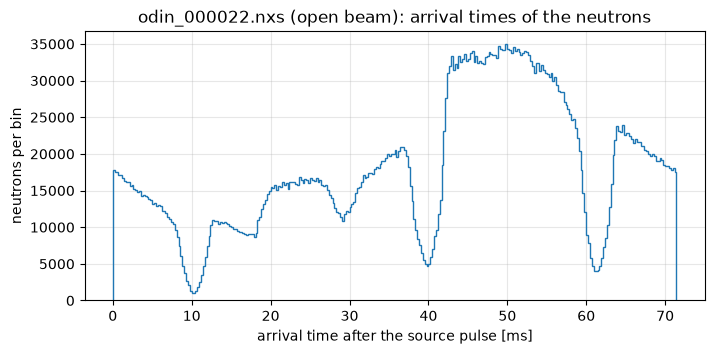

In [6]:
with h5py.File(path(OPEN), "r") as f:
    e = f["entry"]
    print("title       :", e["title"][()].decode())
    print("sample      :", e["sample/name"][()].decode())
    print("start / end :", e["start_time"][()].decode(), "/", e["end_time"][()].decode())
    det = e["instrument/timepix3/data"]
    toa = det["event_time_offset"][()]
    unit = det["event_time_offset"].attrs.get("units", b"ns")
    unit = unit.decode() if isinstance(unit, bytes) else unit
    print("neutrons    :", len(toa), "events,", len(det["event_time_zero"]), "source pulses")
    charge = e["instrument/source/pulse_charge/value"][()]
    print(f"proton charge: {charge.sum():.0f} µC in total ({charge.mean():.1f} µC per pulse on average)")

scale = {"ns": 1e-6, "us": 1e-3, "ms": 1.0, "s": 1e3}.get(unit, 1e-6)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(toa * scale, bins=300, histtype="step", color="tab:blue")
ax.set_xlabel("arrival time after the source pulse [ms]"); ax.set_ylabel("neutrons per bin")
ax.set_title(f"{OPEN} (open beam): arrival times of the neutrons"); ax.grid(alpha=0.3)
plt.show()

The file shown is the open beam: the beam itself, without the sample.

**Reading the histogram.** A slow neutron (long wavelength) takes longer to fly the 60 m from the source to the
detector: the arrival time *is* a measurement of the wavelength, $\lambda = h\,t / (m_n L)$ (de Broglie). In WFM mode
(*wavelength frame multiplication*) the choppers cut the long ESS pulse into several short sub-pulses, the **frames**:
you see them as separate humps, each one covering a band of wavelengths. Converting time to wavelength therefore needs
the chopper settings, which are in the file: this is what the ESS software does in the next step.

## 4. Raw counts: open beam and sample

Before any correction, compare the number of neutrons detected with and without the sample, as a function of the
wavelength (left) and on the detector (right). The wavelength $\lambda$ of every neutron is computed by the official
ESS workflow (`essimaging`) from its arrival time and the chopper settings. The spectrum is summed over the region of
interest (ROI), a square of 6 mm × 6 mm at the center of the detector, where the iron plate is.

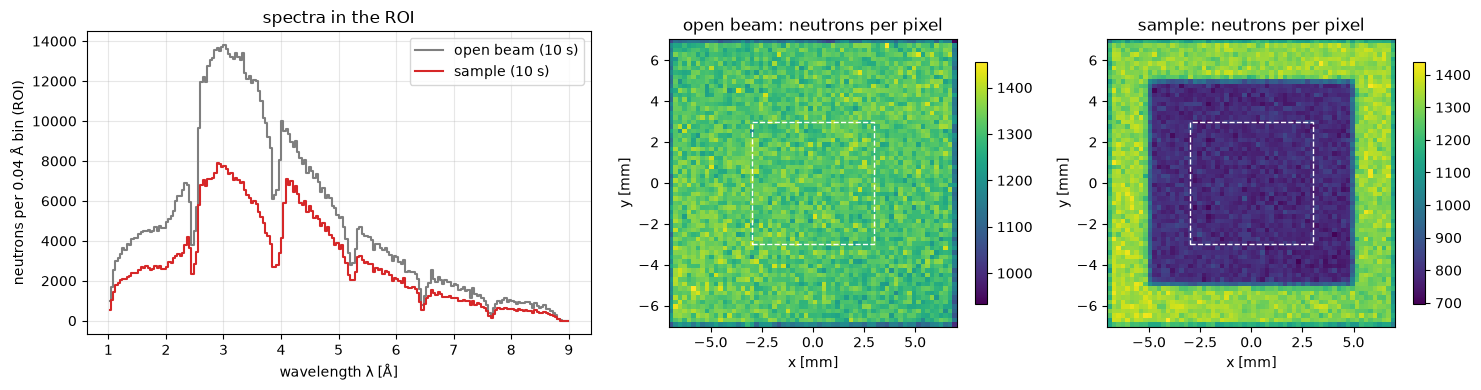

In [7]:
LAM = sc.linspace("wavelength", 1.0, 9.0, 201, unit="angstrom")    # 200 bins of 0.04 Å
ROI = (-3, 3, -3, 3)                                                 # x_min, x_max, y_min, y_max [mm]
raw = {k: red.histograms(path(n), LAM, ROI) for k, n in (("open beam", OPEN), ("sample", SAMPLE))}

lam = sc.midpoints(LAM).values
fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
for (k, h), c in zip(raw.items(), ("tab:gray", "tab:red")):
    ax[0].step(lam, h["spectrum"].values, where="mid", color=c, label=f"{k} ({h['duration']:.0f} s)")
ax[0].set_xlabel("wavelength λ [Å]"); ax[0].set_ylabel("neutrons per 0.04 Å bin (ROI)")
ax[0].set_title("spectra in the ROI"); ax[0].legend(); ax[0].grid(alpha=0.3)
for a, (k, h) in zip(ax[1:], raw.items()):
    im = h["image"]
    x, y = im.coords["x"].values, im.coords["y"].values
    m = a.imshow(im.values, origin="lower", extent=[x[0], x[-1], y[0], y[-1]], cmap="viridis")
    a.add_patch(plt.Rectangle((ROI[0], ROI[2]), ROI[1] - ROI[0], ROI[3] - ROI[2], fill=False, ec="w", ls="--"))
    a.set_title(f"{k}: neutrons per pixel"); a.set_xlabel("x [mm]"); a.set_ylabel("y [mm]")
    plt.colorbar(m, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()

**What to see.** The open-beam spectrum is the shape of the beam: it is not flat (the moderator emits more neutrons
around 2–4 Å) and shows the frames of the choppers. The sample spectrum is lower (iron absorbs and scatters
neutrons) and has **steps**. On the images, the plate (10 mm × 10 mm) is the darker square.

The raw spectra cannot be compared directly: the beam shape is in both, and the two counts may not have received the
same number of protons. The reduction removes all this.

## 5. Reduction: the transmission

The **transmission** is the fraction of neutrons that cross the sample without being absorbed or deflected:

$$T(\lambda) = \frac{\big(S - D\,t_S/t_D\big)\,/\,Q_S}{\big(O - D\,t_O/t_D\big)\,/\,Q_O}$$

- $S$, $O$, $D$: counts of the sample, open beam and dark runs; $t$: their durations;
- the dark is subtracted from both, scaled to the duration of each measurement;
- each measurement is divided by its proton charge $Q$, because the power of the source varies;
- the ratio removes the beam shape: $T = 1$ where nothing is in the beam, $T = 0$ for an opaque sample.

The error bars come from the counting statistics (Poisson: $\sqrt{N}$ on $N$ counts), propagated through the formula.
`red.reduce` does all this with the official ESS code (about 1 min).

{'E': '10 s, 10013 µC', 'O': '10 s, 9989 µC', 'N': '30 s, 29986 µC'} (E: sample, O: open beam, N: dark)


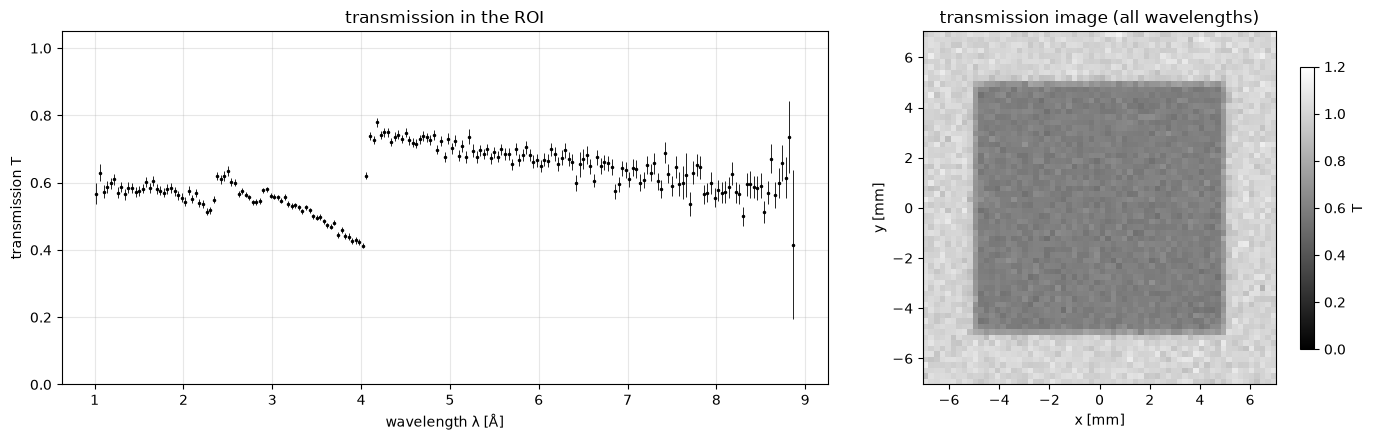

In [8]:
r = red.reduce(path(SAMPLE), path(OPEN), dark=path(DARK), lam=LAM, roi=ROI)
print({k: f"{v['duration']:.0f} s, {v['charge_uC']:.0f} µC" for k, v in r["normalization"].items()},
      "(E: sample, O: open beam, N: dark)")
T, dT = r["spectrum"].values, np.sqrt(r["spectrum"].variances)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].errorbar(lam, T, dT, fmt=".", ms=3, lw=0.6, color="k")
ax[0].set_xlabel("wavelength λ [Å]"); ax[0].set_ylabel("transmission T"); ax[0].set_ylim(0, 1.05)
ax[0].set_title("transmission in the ROI"); ax[0].grid(alpha=0.3)
im = r["image"]; x, y = im.coords["x"].values, im.coords["y"].values
m = ax[1].imshow(im.values, origin="lower", extent=[x[0], x[-1], y[0], y[-1]], cmap="gray", vmin=0, vmax=1.2)
ax[1].set_title("transmission image (all wavelengths)"); ax[1].set_xlabel("x [mm]"); ax[1].set_ylabel("y [mm]")
plt.colorbar(m, ax=ax[1], shrink=0.8, label="T")
plt.tight_layout(); plt.show()

**Reading the figure.** Around the plate the image is close to $T = 1$ (nothing in the beam); on the plate
$T \approx 0.6$. The spectrum on the left is the fingerprint of the material: $T$ drops slowly in some places
and **jumps up** suddenly at a few wavelengths. These jumps are the **Bragg edges**.

**Why a jump?** Iron is a crystal: its atoms sit on planes a distance $d$ apart. Neutrons are deflected (Bragg
diffraction) by the planes when $\lambda = 2d\sin\theta$, $\theta$ being the angle between the neutron and the planes.
Since $\sin\theta \le 1$, a family of planes can deflect only neutrons with $\lambda \le 2d$. Just above $\lambda = 2d$
these planes stop removing neutrons from the beam, so the transmission jumps up. The position of the edge measures
$d$ directly: $d = \lambda_\text{edge}/2$.

## 6. Measuring the Bragg edges

Near an edge, $T(\lambda)$ is fitted with a smoothed step on a sloped baseline:

$$T(\lambda) = A + C\,(\lambda - \lambda_\text{edge}) + \frac{B}{2}\,\mathrm{erfc}\!\left(-\frac{\lambda - \lambda_\text{edge}}{\sqrt{2}\,w}\right)$$

$B$ is the height of the jump, $\lambda_\text{edge}$ its position and $w$ its width (the step is rounded by the
wavelength resolution of the instrument, set by the choppers). `curve_fit` finds the parameters that best match the
points, given their error bars, and the uncertainty of each parameter.

α-iron (ferrite) is body-centered cubic with a lattice parameter $a = 2.8665$ Å. The planes that can diffract are
(110), (200), (211)... with spacings $d_{hkl} = a/\sqrt{h^2+k^2+l^2}$; the expected edges are at $2d_{hkl}$.

(110): edge at 4.0588 ± 4385352.4932 Å (expected 4.0538 Å), jump 0.345 ± 0.011  ->  d = 2.0294 ± 2192676.2466 Å (expected 2.0269 Å)
(200): edge at 2.8783 ± 0.0089 Å (expected 2.8665 Å), jump 0.056 ± 0.011  ->  d = 1.4391 ± 0.0045 Å (expected 1.4332 Å)
(211): edge at 2.3497 ± 0.0055 Å (expected 2.3405 Å), jump 0.130 ± 0.017  ->  d = 1.1748 ± 0.0028 Å (expected 1.1702 Å)


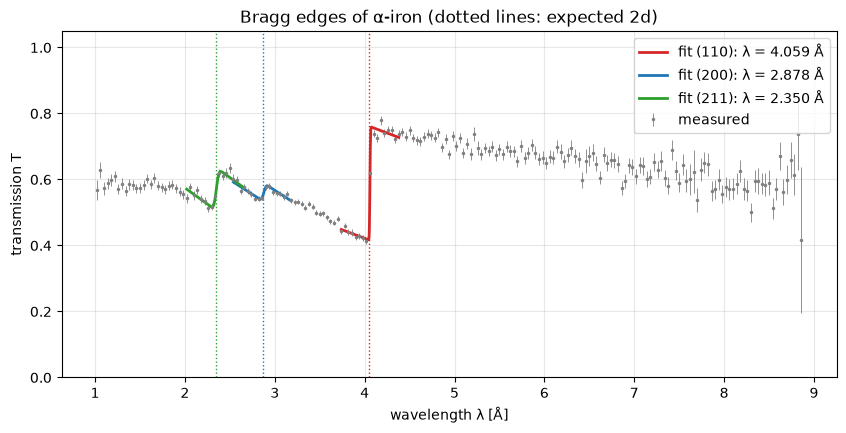

In [9]:
A_FE = 2.8665                                           # Å, lattice parameter of α-iron at room temperature
PLANES = {"(110)": 2, "(200)": 4, "(211)": 6}           # h² + k² + l²

def step(l, l_edge, w, A, C, B):
    return A + C * (l - l_edge) + 0.5 * B * erfc(-(l - l_edge) / (np.sqrt(2) * w))

results = {}
for name, n in PLANES.items():
    expected = 2 * A_FE / np.sqrt(n)
    m = (lam > expected - 0.35) & (lam < expected + 0.35) & np.isfinite(T) & (dT > 0)
    try:
        p, cov = curve_fit(step, lam[m], T[m], sigma=dT[m], absolute_sigma=True,
                           p0=[expected, 0.03, T[m].min(), 0.0, 0.1],
                           bounds=([expected - 0.3, 0.005, 0, -2, 0], [expected + 0.3, 0.3, 2, 2, 1]))
    except RuntimeError:
        print(name, ": no edge found"); continue
    err = np.sqrt(np.diag(cov))
    results[name] = dict(window=m, p=p, expected=expected, lam=p[0], dlam=err[0], jump=p[4], djump=err[4])
    print(f"{name}: edge at {p[0]:.4f} ± {err[0]:.4f} Å (expected {expected:.4f} Å), jump {p[4]:.3f} ± {err[4]:.3f}"
          f"  ->  d = {p[0] / 2:.4f} ± {err[0] / 2:.4f} Å (expected {expected / 2:.4f} Å)")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(lam, T, dT, fmt=".", ms=3, lw=0.6, color="0.5", label="measured")
for (name, res), c in zip(results.items(), ("tab:red", "tab:blue", "tab:green")):
    ll = np.linspace(lam[res["window"]].min(), lam[res["window"]].max(), 300)
    ax.plot(ll, step(ll, *res["p"]), color=c, lw=2, label=f"fit {name}: λ = {res['lam']:.3f} Å")
    ax.axvline(res["expected"], color=c, ls=":", lw=1)
ax.set_xlabel("wavelength λ [Å]"); ax.set_ylabel("transmission T"); ax.set_ylim(0, 1.05)
ax.set_title("Bragg edges of α-iron (dotted lines: expected 2d)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Conclusion.** The (110) edge is the largest and best measured. With the demonstration session (10 s per run) it
comes out at 4.059 ± 0.001 Å, i.e. $d_{110} = 2.030$ Å for an expected 2.027 Å: right to 0.15 %. The smaller edges
are measured less precisely: their jump is smaller compared to the error bars. A jump with an uncertainty as large as
itself is not a measurement: count longer.

**Statistical and systematic errors.** The difference on the (110) edge (0.005 Å) is about 4 times its uncertainty:
it is not a fluctuation of the counting, which would shrink by counting longer, but a small **systematic** error. It
comes from the conversion of the arrival time into a wavelength (the flight distances and chopper timings assumed by
the reduction). Real instruments have the same problem: they calibrate the wavelength by measuring a reference powder
whose plane spacings are known, and correct the scale.

**A word of honesty.** These data come from a simulation (McStas, with the crystal description of iron from NCrystal),
not from a real instrument. The analysis, however, is exactly the one you would do at ESS, with the same files and the
same reduction software.

## 7. Going further

1. Compute the lattice parameter $a$ of iron from your (110) edge, with its uncertainty. Compare with 2.8665 Å.
2. Count 4 times longer (sample and open beam). By how much do the error bars on $T$ and on $\lambda_\text{edge}$
   shrink? Compare with what Poisson statistics predicts ($\sqrt{4} = 2$).
3. Measure with `wfm_delta` = 0.10 m and 0.45 m, then in `natural` mode. How do the width $w$ of the edge and the
   number of neutrons change? Why is this a compromise?
4. Move the ROI (cell of part 4) onto a region **without** the plate. What transmission do you expect, and what do you
   get?
5. (Master) Fit the (110) edge with a 2× wider and a 2× narrower window. Does $\lambda_\text{edge}$ move by more than
   its uncertainty? What does this tell you about systematic errors?